# Random Forest for competency-based mentor matching

Study: *Comparing Machine Learning Methods for Matching Mentors’ Teaching Competencies with Mentees’ Professional Development Needs in Higher Education*.

This notebook trains a **random forest** (500 trees, minimum leaf size 5, balanced class weights).

The data preparation, grouped split (seed 42), five lexical features and the validation-based threshold rule are **identical** to `LogisticRegression.ipynb`, so the results can be compared directly (RQ1, hypotheses H0/H1). Data: manually annotated UniSkill records (https://huggingface.co/datasets/nurlanm/UniSkill_dataset).

## 1. Load and verify the data

In [1]:
# Paths: works in Google Colab (files in Google Drive) and on a local computer.
from pathlib import Path
import hashlib, json, re, time, warnings, platform, importlib.metadata
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Assignment3_TulegenovaK')  # folder with manual_records.csv
except ImportError:
    BASE = Path.cwd()  # local run: the notebook sits next to manual_records.csv

RESULT = BASE / 'results'
RESULT.mkdir(exist_ok=True)
SEED = 42

versions = {'python': platform.python_version(),
            **{p: importlib.metadata.version(p) for p in ['pandas', 'numpy', 'scipy', 'scikit-learn', 'matplotlib']}}
print(json.dumps(versions, indent=2))

# Integrity check: the CSV must be the same file that was verified in the source manifest.
manifest = json.loads((BASE / 'source_manifest.json').read_text(encoding='utf-8'))
assert hashlib.sha256((BASE / 'manual_records.csv').read_bytes()).hexdigest() == manifest['manual_csv_sha256']
raw = pd.read_csv(BASE / 'manual_records.csv')
print('Manual UniSkill records:', len(raw))

{
  "python": "3.9.6",
  "pandas": "2.3.3",
  "numpy": "2.0.2",
  "scipy": "1.13.1",
  "scikit-learn": "1.6.1",
  "matplotlib": "3.9.4"
}
Manual UniSkill records: 1098


## 2. Clean the data, build leakage-free groups and compute features

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1) Cleaning (identical to the Logistic Regression notebook)
TEXT_COLS = ['skill_label', 'skill_description', 'matched_course_sentence', 'course_title']
df = raw.copy()
for c in TEXT_COLS:
    df[c] = df[c].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
df = df.drop_duplicates(TEXT_COLS).reset_index(drop=True)
df['record_id'] = [f'R{i:04d}' for i in range(len(df))]
df['skill_text'] = df.skill_label + ' ' + df.skill_description
y = df.eval_all.astype(int).to_numpy()

# 2) Connected groups: records that share a course title or a course sentence stay together
parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
for col in ['course_title', 'matched_course_sentence']:
    seen = {}
    for i, t in enumerate(df[col]):
        k = t.casefold()
        if k in seen:
            parent[find(seen[k])] = find(i)
        else:
            seen[k] = i
df['group'] = [find(i) for i in range(len(df))]

def grouped_split(seed):
    """20% of groups -> test, 25% of the remaining groups -> validation."""
    dev, test = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(df, groups=df.group))
    a, b = next(GroupShuffleSplit(1, test_size=0.25, random_state=seed).split(df.iloc[dev], groups=df.group.iloc[dev]))
    return dev[a], dev[b], test

# 3) Five lexical features (TF-IDF is fitted on training text only)
def jaccard(a, b):
    a, b = set(re.findall(r'\b\w+\b', a.casefold())), set(re.findall(r'\b\w+\b', b.casefold()))
    return len(a & b) / len(a | b) if a | b else 0.0
JAC_S = np.array([jaccard(a, b) for a, b in zip(df.matched_course_sentence, df.skill_label)])
JAC_T = np.array([jaccard(a, b) for a, b in zip(df.course_title, df.skill_label)])
FEATURES = ['cos_sentence', 'cos_title', 'cos_min', 'jaccard_sentence', 'jaccard_title']

def lexical_features(train_idx):
    vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=20000, norm='l2')
    t = df.iloc[train_idx]
    vec.fit(pd.concat([t.course_title, t.matched_course_sentence, t.skill_text]).tolist())
    sk, ti, se = (vec.transform(df[c]) for c in ['skill_text', 'course_title', 'matched_course_sentence'])
    cs = np.asarray(se.multiply(sk).sum(1)).ravel()
    ct = np.asarray(ti.multiply(sk).sum(1)).ravel()
    return np.column_stack([cs, ct, np.minimum(cs, ct), JAC_S, JAC_T])

# 4) Threshold choice on validation data and evaluation helpers
THRESHOLDS = np.linspace(0.05, 0.95, 19)
def pick_threshold(y_val, p_val, grid=THRESHOLDS):
    scores = [(f1_score(y_val, p_val >= t, average='macro', zero_division=0), t) for t in grid]
    best = max(s for s, _ in scores)
    return min((t for s, t in scores if s == best), key=lambda t: (abs(t - 0.5), t))

def evaluate(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0),
                f1_match=f1_score(y_true, y_pred, zero_division=0),
                macro_f1=f1_score(y_true, y_pred, average='macro', zero_division=0),
                TN=int(cm[0, 0]), FP=int(cm[0, 1]), FN=int(cm[1, 0]), TP=int(cm[1, 1]))

train_idx, val_idx, test_idx = grouped_split(SEED)
X = lexical_features(train_idx)
print('Clean records:', len(df), '| classes:', dict(zip(*np.unique(y, return_counts=True))))
print('Connected groups:', df.group.nunique(), '| largest group:', df.groupby('group').size().max())
print('Split sizes (train / validation / test):', len(train_idx), len(val_idx), len(test_idx))
assert (len(train_idx), len(val_idx), len(test_idx)) == (649, 231, 216), 'Split differs from the LR notebook'
for a, b in [(train_idx, val_idx), (train_idx, test_idx), (val_idx, test_idx)]:
    assert not set(df.group.iloc[a]) & set(df.group.iloc[b])
print('Feature matrix:', X.shape)

Clean records: 1096 | classes: {np.int64(0): np.int64(700), np.int64(1): np.int64(396)}
Connected groups: 544 | largest group: 21
Split sizes (train / validation / test): 649 231 216
Feature matrix: (1096, 5)


## 3. Train the model and choose the decision threshold on the validation set

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

def make_models(seed):
    """Hyperparameters are fixed in advance and identical for every split."""
    return {
        'LR': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000, class_weight='balanced', random_state=seed)),
        'RF': RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight='balanced', random_state=seed, n_jobs=-1),
        'GB': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=seed),
    }
NAMES = {'LR': 'Logistic regression', 'RF': 'Random forest', 'GB': 'Gradient boosting',
         'Cosine': 'Cosine baseline', 'Majority': 'Majority baseline'}

model = make_models(SEED)['RF']
start = time.perf_counter()
model.fit(X[train_idx], y[train_idx])
train_seconds = time.perf_counter() - start
prob = model.predict_proba(X)[:, 1]
threshold = pick_threshold(y[val_idx], prob[val_idx])
print(model)
print(f'Training time: {train_seconds:.2f} s')
print(f'Validation-selected threshold: {threshold:.2f}')
print(f'Validation macro-F1: {f1_score(y[val_idx], prob[val_idx] >= threshold, average="macro"):.4f}')

RandomForestClassifier(class_weight='balanced', min_samples_leaf=5,
                       n_estimators=500, n_jobs=-1, random_state=42)
Training time: 0.51 s
Validation-selected threshold: 0.50
Validation macro-F1: 0.6616


## 4. Evaluate on the held-out test set (216 pairs)

For reference, Logistic Regression is trained on exactly the same split.

In [4]:
pred = (prob[test_idx] >= threshold).astype(int)
row = dict(method='Random Forest', threshold=threshold, **evaluate(y[test_idx], pred))

lr = make_models(SEED)['LR'].fit(X[train_idx], y[train_idx])
lr_prob = lr.predict_proba(X)[:, 1]
lr_t = pick_threshold(y[val_idx], lr_prob[val_idx])
lr_row = dict(method='Logistic regression (reference)', threshold=lr_t,
              **evaluate(y[test_idx], (lr_prob[test_idx] >= lr_t).astype(int)))

metrics = pd.DataFrame([row, lr_row])
print(metrics.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
metrics.to_csv(RESULT / 'rf_test_metrics.csv', index=False)

out = df.iloc[test_idx][['record_id', 'skill_label', 'course_title', 'matched_course_sentence',
                         'eval_all_tit', 'eval_all_sen', 'eval_all']].copy()
out['probability'] = prob[test_idx]
out['prediction'] = pred
out.to_csv(RESULT / 'rf_test_predictions.csv', index=False)
errors = out[out.prediction != out.eval_all]
errors.to_csv(RESULT / 'rf_errors.csv', index=False)
print('Misclassified test pairs:', len(errors), '| missed matches (FN):', int((errors.eval_all == 1).sum()),
      '| false matches (FP):', int((errors.eval_all == 0).sum()))

                         method  threshold  accuracy  precision  recall  f1_match  macro_f1  TN  FP  FN  TP
                  Random Forest     0.5000    0.7176     0.6095  0.7619    0.6772    0.7131  91  41  20  64
Logistic regression (reference)     0.5500    0.7269     0.7049  0.5119    0.5931    0.6938 114  18  41  43
Misclassified test pairs: 61 | missed matches (FN): 20 | false matches (FP): 41


## 5. Visualise the results

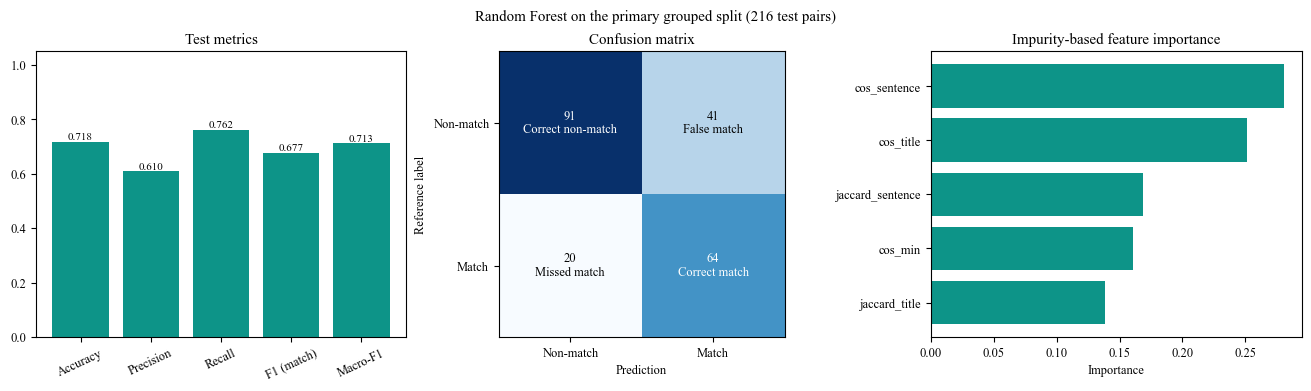

cos_sentence        0.281
cos_title           0.251
jaccard_sentence    0.169
cos_min             0.161
jaccard_title       0.138


In [5]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'], 'font.size': 9})

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
labels = ['Accuracy', 'Precision', 'Recall', 'F1 (match)', 'Macro-F1']
vals = [row['accuracy'], row['precision'], row['recall'], row['f1_match'], row['macro_f1']]
b = axes[0].bar(labels, vals, color='#0d9488')
axes[0].bar_label(b, labels=[f'{v:.3f}' for v in vals], fontsize=8)
axes[0].set_ylim(0, 1.05); axes[0].set_title('Test metrics'); axes[0].tick_params(axis='x', rotation=25)

cm = confusion_matrix(y[test_idx], pred, labels=[0, 1])
axes[1].imshow(cm, cmap='Blues')
names = [['Correct non-match', 'False match'], ['Missed match', 'Correct match']]
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f'{cm[i, j]}\n{names[i][j]}', ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else 'black')
axes[1].set_xticks([0, 1], ['Non-match', 'Match']); axes[1].set_yticks([0, 1], ['Non-match', 'Match'])
axes[1].set_xlabel('Prediction'); axes[1].set_ylabel('Reference label'); axes[1].set_title('Confusion matrix')

imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
axes[2].barh(imp.index, imp.values, color='#0d9488')
axes[2].set_title('Impurity-based feature importance'); axes[2].set_xlabel('Importance')
fig.suptitle('Random Forest on the primary grouped split (216 test pairs)')
fig.savefig(RESULT / 'rf_results.png', dpi=200, bbox_inches='tight')
plt.show()
print(imp.sort_values(ascending=False).round(3).to_string())

## 6. Note

A single split is not enough to rank the models: the formal test of H0 uses 30 repeated grouped splits in `04_Model_Comparison_and_Hypothesis_Testing.ipynb`. The errors of this model are interpreted in `05_Qualitative_Error_Analysis.ipynb`. The records are course–competency pairs, a proxy for mentor–mentee matching; no personal data were used.